# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [ ]:
ПІБ = 'Мартин Максим Ігорович'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-31'      # напр. 'КН-31'
ВАРІАНТ = 14     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [1]:
%pip install "pulp[cbc]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 191.3/191.3 MB 5.7 MB/s eta 0:00:00


In [ ]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 14 · Мартин Максим Ігорович, ШІ-31, «Longer Boats»
Підприємство «Longer Boats» виготовляє яхти. Одиниця виміру плану: шт./місяць.

                       Sting  Ray  Breaker  Marlin  ЗАПАС
Склопластик, м²            4    3        3       4    969
Столярний цех, год         6    6        1       6    672
Фарбувальний цех, год      1    3        5       1   1364
Такелаж, компл.            1    5        1       4    878
Ділянка добудови, год      4    4        0       3    618

                    Sting  Ray  Breaker  Marlin
Прибуток з одиниці     26   56       41      40

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Фарбувальний цех, год
  ціна:   5.0 за одиницю
  обсяг:  до 222 одиниць


In [ ]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

Змінні рішення: `x1, x2, x3, x4` — скільки яхт Sting, Ray, Breaker і Marlin «Longer Boats» випускає за місяць, шт./місяць.

Цільова функція (місячний прибуток, робимо найбільшим):

`Z = 26·x1 + 56·x2 + 41·x3 + 40·x4 → max`

Обмеження (на план іде не більше ресурсу, ніж є на складі):
```
4·x1 + 3·x2 + 3·x3 + 4·x4 ≤  969   (склопластик, м²)
6·x1 + 6·x2 + 1·x3 + 6·x4 ≤  672   (столярний цех, год)
1·x1 + 3·x2 + 5·x3 + 1·x4 ≤ 1364   (фарбувальний цех, год)
1·x1 + 5·x2 + 1·x3 + 4·x4 ≤  878   (такелаж, компл.)
4·x1 + 4·x2 + 0·x3 + 3·x4 ≤  618   (ділянка добудови, год)
```

Невід'ємність: `x1, x2, x3, x4 ≥ 0`.

Коротко в матричному вигляді: `max c·x` при `A·x ≤ b`, `x ≥ 0`, де `A` — матриця витрат 5×4, `b` — запаси, `c` — прибутки з одиниці.


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:** Запас є параметром, бо підприємство його не обирає: на плановий місяць є рівно 969 м² склопластику, 672 год столярного цеху і так далі. Ці числа задані ззовні так само, як витрати на виріб і прибуток. Змінна рішення — лише те, чим ми керуємо, тобто скільки яких яхт випускати.

Якби ресурс можна було докупити в будь-якій кількості, докуплений обсяг став би новою змінною `y_i ≥ 0`. Обмеження набуло б вигляду `A_i·x ≤ b_i + y_i`, а з прибутку віднімалася б вартість закупівлі: `Z = c·x − Σ p_i·y_i`. Дефіцитний ресурс, дешевший за свою тіньову ціну, модель докуповувала б, доки не впреться в інше обмеження. А якщо обмежень на закупівлю немає взагалі і всі ресурси для якогось виробу разом коштують менше, ніж він приносить, задача стає необмеженою: прибуток росте без кінця. Тому пропозиція постачальника на етапі 6 має і ціну, і граничний обсяг.


---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [ ]:
# впишіть числа, які дав Excel
# (Solver, Simplex LP; звіт показує їх з 8–9 знаками після коми)
EXCEL_ПЛАН    = [0, 73.92592593, 228.44444444, 0]     # Sting, Ray, Breaker, Marlin, шт./міс.
EXCEL_ПРИБУТОК = 13506.07407                          # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [0, 73.92592593, 228.44444444, 0] | прибуток 13506.07407


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [ ]:
# Та сама модель, що в Excel: max c·x при A·x <= b, x >= 0.
# linprog уміє лише мінімізувати, тому передаємо -c, а прибуток беремо як -r.fun.
r = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * 4, method='highs')
assert r.status == 0, r.message          # 0 означає «оптимум знайдено»

план = r.x                               # оптимальний випуск кожного виробу
прибуток = -r.fun                        # максимальний прибуток

# Тіньові ціни linprog віддає для задачі на мінімум, тобто зі знаком мінус.
# Для нашої задачі на максимум знак міняємо.
тіньові = -r.ineqlin.marginals
використано = A @ план                   # скільки кожного ресурсу пішло на план
залишок = b - використано

print('Оптимальний план, шт./міс.:')
print(pd.Series(план, index=вироби).round(3).to_string())
print('\nМаксимальний прибуток: %.2f' % прибуток)
print()
print(pd.DataFrame({'використано': використано, 'запас': b, 'залишок': залишок,
                    'тіньова ціна': тіньові}, index=ресурси).round(3).to_string())

Оптимальний план, шт./міс.:
Sting        0.000
Ray         73.926
Breaker    228.444
Marlin       0.000

Максимальний прибуток: 13506.07

                       використано   запас  залишок  тіньова ціна
Склопластик, м²            907.111   969.0   61.889         0.000
Столярний цех, год         672.000   672.0    0.000         5.815
Фарбувальний цех, год     1364.000  1364.0    0.000         7.037
Такелаж, компл.            598.074   878.0  279.926         0.000
Ділянка добудови, год      295.704   618.0  322.296         0.000


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [ ]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

Числа зі звіту про стійкість Excel (аркуш «Sensitivity Report», Solver від Frontline у веб-версії Excel), округлені до трьох знаків. `1E+30` — так Excel записує нескінченність.

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Склопластик, м² | 907.111 | 0 | 969 | 1E+30 | 61.889 |
| Столярний цех, год | 672 | 5.815 | 672 | 278.5 | 399.2 |
| Фарбувальний цех, год | 1364 | 7.037 | 1364 | 111.4 | 1028 |
| Такелаж, компл. | 598.074 | 0 | 878 | 1E+30 | 279.926 |
| Ділянка добудови, год | 295.704 | 0 | 618 | 1E+30 | 322.296 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

У дефіциті столярний і фарбувальний цехи. Їхнє кінцеве значення дорівнює правій частині (672 з 672 і 1364 з 1364 год), а тіньова ціна додатна: 5.815 і 7.037. Тобто кожна додаткова година столярного цеху дала б +5.815 прибутку, а фарбувального +7.037.

Решта три ресурси в надлишку: склопластику лишається 61.9 м², такелажу 279.9 компл., ділянки добудови 322.3 год. Тіньова ціна в них 0, а допустиме збільшення 1E+30: докуповувати те, чого й так не використано повністю, немає сенсу. Їхнє допустиме зменшення дорівнює саме залишку, бо забрати без шкоди для плану можна лише невикористане.


### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Sting | 0 | −15.926 | 26 | 15.926 | 1E+30 |
| Ray | 73.926 | 0 | 56 | 190 | 1.793 |
| Breaker | 228.444 | 0 | 41 | 4.333 | 31.667 |
| Marlin | 0 | −1.926 | 40 | 1.926 | 1E+30 |


Веб-версія Solver показує в цьому блоці не допустимі зміни, а межі коефіцієнта (Maximum і Minimum Objective Coefficient). Допустиме збільшення = Maximum − коефіцієнт, допустиме зменшення = коефіцієнт − Minimum. Наприклад, для Ray: 246 − 56 = 190 і 56 − 54.207 = 1.793.


**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

Не виробляються два вироби: Sting і Marlin. Щоб Sting увійшов у план, його прибуток з одиниці мав би зрости на 15.926 (з 26 до 41.926), а Marlin лише на 1.926 (з 40 до 41.926). Це число стоїть у звіті двічі: як зведена вартість (зі знаком мінус) і як допустиме збільшення цільового коефіцієнта.

Звідки воно береться. Одна яхта Sting чи Marlin забирає 6 год столярного і 1 год фарбувального цеху, тобто саме ті ресурси, які зараз повністю зайняті під Ray і Breaker. За тіньовими цінами ці ресурси коштують `6·5.815 + 1·7.037 = 41.926`. Виріб варто випускати лише тоді, коли він приносить не менше, ніж коштують ресурси, які він забирає в інших. Sting приносить 26, Marlin 40, тому обидва програють, а Marlin стоїть майже на межі. Звідси й мале допустиме зменшення для Ray (1.793): якщо прибуток з Ray упаде нижче 54.207, вигіднішим стане Marlin.


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [ ]:
def розвязати(запаси):
    """Розв'язує виробничу задачу з іншими запасами; повертає (прибуток, план)."""
    rr = linprog(-c, A_ub=A, b_ub=запаси, bounds=[(0, None)] * 4, method='highs')
    return -rr.fun, rr.x

i_max = int(np.argmax(тіньові))          # ресурс з найбільшою тіньовою ціною
ТІНЬОВА_EXCEL = 7.037037037               # «Тіньова ціна» цього ресурсу зі звіту Excel
ЗБІЛЬШЕННЯ_EXCEL = 111.4                  # його «Допустиме збільшення» зі звіту

b_plus1 = b.copy()
b_plus1[i_max] += 1                       # +1 одиниця найдорожчого ресурсу
прибуток_plus1, план_plus1 = розвязати(b_plus1)
приріст = прибуток_plus1 - прибуток

print('Найдорожчий ресурс:', ресурси[i_max])
print('Прибуток: %.4f -> %.4f' % (прибуток, прибуток_plus1))
print('Приріст від +1 год:      %.6f' % приріст)
print('Тіньова ціна зі звіту:   %.6f' % ТІНЬОВА_EXCEL)
assert abs(приріст - ТІНЬОВА_EXCEL) < 1e-6, 'приріст не дорівнює тіньовій ціні'
print('Збігаються: так')
print('План змінився так:', ', '.join('%s %+.3f' % (v, d) for v, d in zip(вироби, план_plus1 - план)))

Найдорожчий ресурс: Фарбувальний цех, год
Прибуток: 13506.0741 -> 13513.1111
Приріст від +1 год:      7.037037
Тіньова ціна зі звіту:   7.037037
Збігаються: так
План змінився так: Sting +0.000, Ray -0.037, Breaker +0.222, Marlin +0.000


**Відповідь 5.1:** Найдорожчий ресурс — фарбувальний цех. Після +1 год прибуток зріс з 13 506.074 до 13 513.111, тобто приріст 7.037037, а тіньова ціна зі звіту 7.037037. Збігаються до шостого знака, отже звіт каже правду: перша додаткова година фарбування справді дає +7.037. Ця година не йде на якийсь один виріб, а перебудовує план: Breaker зростає на 0.222 шт., Ray зменшується на 0.037 шт.


### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

Приріст = 7.037 на перших 111 кроках (до 1475 год)
Крок 1475 -> 1476 год дає лише 2.815
Далі приріст = 0.000
Межа з прогону: між +111 і +112 год; у звіті Excel: +111.4


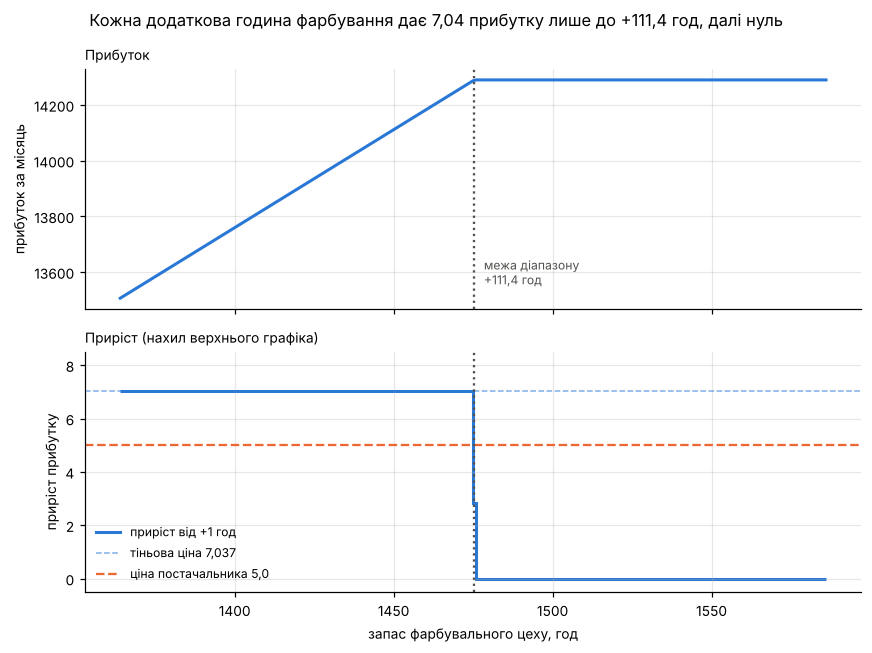

In [ ]:
# Запас фарбувального цеху від базового значення вгору з кроком 1.
# Верхня межа = база + обсяг пропозиції постачальника (222 год), щоб на графіку
# було видно і межу діапазону, і що буде, якщо купити все.
обсяг = V['обсяг_пропозиції']
запаси_ресурсу = np.arange(b[i_max], b[i_max] + обсяг + 1)     # 1364, 1365, ..., 1586
прибутки = []
for q in запаси_ресурсу:
    bb = b.copy()
    bb[i_max] = q
    прибутки.append(розвязати(bb)[0])
прибутки = np.array(прибутки)
нахил = np.diff(прибутки)          # приріст прибутку від кожної наступної години

# Межа: перший крок, на якому приріст перестав дорівнювати тіньовій ціні
k0 = int(np.argmax(np.abs(нахил - ТІНЬОВА_EXCEL) > 1e-6))
print('Приріст = %.3f на перших %d кроках (до %d год)' % (ТІНЬОВА_EXCEL, k0, запаси_ресурсу[k0]))
print('Крок %d -> %d год дає лише %.3f' % (запаси_ресурсу[k0], запаси_ресурсу[k0 + 1], нахил[k0]))
print('Далі приріст = %.3f' % нахил[k0 + 1])
print('Межа з прогону: між +%d і +%d год; у звіті Excel: +%.1f' % (k0, k0 + 1, ЗБІЛЬШЕННЯ_EXCEL))

СИНІЙ, ПОМАРАНЧЕВИЙ, СІРИЙ = '#2a78d6', '#eb6834', '#52514e'
межа = b[i_max] + ЗБІЛЬШЕННЯ_EXCEL
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(запаси_ресурсу, прибутки, color=СИНІЙ, lw=2)
ax1.axvline(межа, color=СІРИЙ, ls=':', lw=1.5)
ax1.text(межа + 3, прибутки.min() + 50, 'межа діапазону\n+111,4 год', color=СІРИЙ, fontsize=8)
ax1.set_ylabel('прибуток за місяць')
ax1.set_title('Прибуток', loc='left', fontsize=9)
ax1.grid(alpha=0.3)

ax2.stairs(нахил, запаси_ресурсу, baseline=None, color=СИНІЙ, lw=2, label='приріст від +1 год')
ax2.axhline(ТІНЬОВА_EXCEL, color=СИНІЙ, ls='--', lw=1, alpha=0.6, label='тіньова ціна 7,037')
ax2.axhline(V['ціна_пропозиції'], color=ПОМАРАНЧЕВИЙ, ls='--', lw=1.5, label='ціна постачальника 5,0')
ax2.axvline(межа, color=СІРИЙ, ls=':', lw=1.5)
ax2.set_ylim(-0.5, 8.5)
ax2.set_ylabel('приріст прибутку')
ax2.set_xlabel('запас фарбувального цеху, год')
ax2.set_title('Приріст (нахил верхнього графіка)', loc='left', fontsize=9)
ax2.legend(loc='lower left', fontsize=8, frameon=False)
ax2.grid(alpha=0.3)
fig.suptitle('Кожна додаткова година фарбування дає 7,04 прибутку лише до +111,4 год, далі нуль')
plt.tight_layout()
plt.show()

**Відповідь 5.2:** Запас фарбувального цеху можна збільшити на 111.4 год, перш ніж тіньова ціна зміниться. Прогін з кроком 1 дає 111 кроків з приростом рівно 7.037. Крок з 1475 на 1476 год дає лише 2.815, тобто `0.4 · 7.037`: за старою ціною працюють тільки перші 0.4 год цього кроку. Далі приріст 0. Отже, межа лежить між +111 і +112 год і збігається з допустимим збільшенням 111.4 зі звіту Excel.

Чому саме там злам: при запасі 1475.4 год план Ray 69.8 і Breaker 253.2 витрачає `3·69.8 + 3·253.2 = 969` м² склопластику, тобто весь запас. Далі вузьким місцем стає склопластик, і додаткові години фарбування нема на що використати.


---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [ ]:
ціна = V['ціна_пропозиції']                # 5.0 за годину
тіньова = ТІНЬОВА_EXCEL                      # 7.037 зі звіту

# 1) Брати чи ні: година дає тіньову ціну прибутку, а коштує ціну пропозиції
брати = тіньова > ціна
print('1) Брати? Тіньова ціна %.3f, ціна %.1f -> %s' % (тіньова, ціна, 'так' if брати else 'ні'))

# 2) Скільки: тіньова ціна чинна лише в межах допустимого збільшення
скільки = min(ЗБІЛЬШЕННЯ_EXCEL, обсяг)       # 111.4 год із 222 запропонованих
скільки_цілих = int(np.floor(скільки))        # 111, якщо продають лише цілі години
print('2) Купувати %.1f год (цілими годинами %d) із %d запропонованих' % (скільки, скільки_цілих, обсяг))

# 3) Виграш за звітом: (тіньова ціна - ціна) * кількість
виграш_звіт = (тіньова - ціна) * скільки
print('3) Виграш за звітом: (%.3f - %.1f) * %.1f = %.2f' % (тіньова, ціна, скільки, виграш_звіт))

def результат_закупівлі(купити):
    """Пряме розв'язання з новим запасом: (новий прибуток, приріст, оплата, чистий виграш)."""
    bb = b.copy()
    bb[i_max] += купити
    новий = розвязати(bb)[0]
    return новий, новий - прибуток, ціна * купити, новий - прибуток - ціна * купити

новий, приріст_пр, оплата, чистий = результат_закупівлі(скільки)
print('   Перевірка прямим розв’язанням: прибуток %.2f -> %.2f, приріст %.2f, оплата %.2f, чистий виграш %.2f'
      % (прибуток, новий, приріст_пр, оплата, чистий))
assert abs(чистий - виграш_звіт) < 1e-6

# Що буде за інших обсягів закупівлі
варіанти = [0, 50, 100, скільки_цілих, скільки, скільки_цілих + 1, 150, обсяг]
табл = pd.DataFrame([результат_закупівлі(v)[1:] for v in варіанти],
                    columns=['приріст прибутку', 'оплата', 'чистий виграш'])
табл.insert(0, 'купити, год', варіанти)
print()
print(табл.round(2).to_string(index=False))

1) Брати? Тіньова ціна 7.037, ціна 5.0 -> так
2) Купувати 111.4 год (цілими годинами 111) із 222 запропонованих
3) Виграш за звітом: (7.037 - 5.0) * 111.4 = 226.93
   Перевірка прямим розв’язанням: прибуток 13506.07 -> 14290.00, приріст 783.93, оплата 557.00, чистий виграш 226.93

 купити, год  приріст прибутку  оплата  чистий виграш
         0.0              0.00     0.0           0.00
        50.0            351.85   250.0         101.85
       100.0            703.70   500.0         203.70
       111.0            781.11   555.0         226.11
       111.4            783.93   557.0         226.93
       112.0            783.93   560.0         223.93
       150.0            783.93   750.0          33.93
       222.0            783.93  1110.0        -326.07


**Відповідь 6.1:**

* Брати чи ні і чому: брати. Тіньова ціна фарбувального цеху 7.037 більша за ціну пропозиції 5.0: кожна куплена година приносить 7.037 прибутку, а коштує 5.0, тож чистий виграш 2.037 з години.
* Скільки одиниць має сенс купити і чому не більше: 111.4 год (якщо продають лише цілі години, то 111) із 222 запропонованих. Тіньова ціна 7.037 чинна тільки в межах допустимого збільшення 111.4 год, а далі падає до 0, бо закінчується склопластик. Кожна година понад 111.4 коштує 5.0 і не дає нічого. Якщо взяти всі 222 год, приріст прибутку буде той самий 783.93, а оплата 1110, тобто збиток 326.07.
* Очікуваний виграш: `(7.037 − 5.0) · 111.4 = 226.93` (для 111 год: 226.11).
* Перевірка прямим розв'язанням дала: із запасом 1364 + 111.4 = 1475.4 год прибуток 14 290.00 замість 13 506.07, приріст 783.93, мінус оплата `111.4 · 5 = 557.00`, чистий виграш 226.93. Збігається з розрахунком за звітом.


---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [ ]:
ненульових = int(np.sum(план > 1e-6))                  # вироби з ненульовим випуском
звязних = int(np.sum(np.abs(A @ план - b) < 1e-6))    # ресурси, витрачені повністю
print('ненульові вироби:', [вироби[j] for j in range(4) if план[j] > 1e-6])
print('зв’язні обмеження:', [ресурси[i] for i in range(5) if abs((A @ план - b)[i]) < 1e-6])

# Для ілюстрації, що означала б розбіжність: якщо докупити рівно 111.4 год фарбування,
# закінчиться ще й склопластик, і зв'язних обмежень стане більше, ніж ненульових виробів.
bb = b.copy()
bb[i_max] += ЗБІЛЬШЕННЯ_EXCEL
P_межа, план_межа = розвязати(bb)
e = np.zeros(5)
e[i_max] = 1
print('\nНа межі діапазону (запас %.1f год): ненульових %d, зв’язних %d'
      % (bb[i_max], np.sum(план_межа > 1e-6), np.sum(np.abs(A @ план_межа - bb) < 1e-6)))
print('  -1 год фарбування змінює прибуток на %.3f' % (розвязати(bb - e)[0] - P_межа))
print('  +1 год фарбування змінює прибуток на %.3f' % (розвязати(bb + e)[0] - P_межа))

ненульові вироби: ['Ray', 'Breaker']
зв’язні обмеження: ['Столярний цех, год', 'Фарбувальний цех, год']

На межі діапазону (запас 1475.4 год): ненульових 2, зв’язних 3
  -1 год фарбування змінює прибуток на -7.037
  +1 год фарбування змінює прибуток на 0.000


In [ ]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** Числа збіглися: 2 ненульові вироби (Ray і Breaker) і 2 зв'язні обмеження (столярний і фарбувальний цехи). Це не випадковість. У розв'язку симплекс-методу базисних змінних стільки ж, скільки обмежень, тут 5. Базисні змінні — це ненульові вироби (2) і залишки недовикористаних ресурсів (3: склопластик, такелаж, добудова). Звідси `ненульові + незв'язні = 5 = зв'язні + незв'язні`, тобто ненульових стільки ж, скільки зв'язних.

Розбіжність означала б вироджений розв'язок: якийсь ресурс витрачено повністю «збігом», а не тому, що він обмежує план. Тоді тіньові ціни не єдині, і звіту про стійкість не можна вірити на слово. У моєму варіанті так стається рівно на межі діапазону: якщо докупити 111.4 год фарбування, зв'язних стає 3 при 2 ненульових виробах. У цій точці мінус одна година фарбування коштує 7.037, а плюс одна година не дає нічого, і одним числом «тіньова ціна» таку точку не описати. На практиці розбіжність — сигнал перевірити звіт прогоном, як на етапі 5.


---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [ ]:
def оцінити(x):
    """Повертає (допустимий?, прибуток, на скільки перевищено запас кожного ресурсу)."""
    x = np.asarray(x, float)
    перевищення = np.maximum(A @ x - b, 0)
    return bool(np.all(перевищення < 1e-9)), float(c @ x), перевищення

# integrality=1 означає «змінна має бути цілою» (працює в scipy >= 1.9)
r_int = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * 4, method='highs',
                integrality=np.ones(4))
assert r_int.status == 0, r_int.message

варіанти_плану = {
    'без умови цілочисельності': план,
    'округлений': np.round(план),
    'цілочисельний оптимум': np.round(r_int.x),
    'округлений вгору (для порівняння)': np.ceil(план.round(6)),
    'округлений вниз (для порівняння)': np.floor(план.round(6)),
}
рядки = []
for назва, x in варіанти_плану.items():
    ok, z, over = оцінити(x)
    порушено = ', '.join('%s +%g' % (ресурси[i].split(',')[0], over[i]) for i in range(5) if over[i] > 1e-9)
    рядки.append([назва, '(' + '; '.join('%g' % round(v, 3) for v in x) + ')', round(z, 2),
                  'так' if ok else 'ні: ' + порушено])
print(pd.DataFrame(рядки, columns=['варіант', 'план', 'прибуток', 'допустимий?']).to_string(index=False))
print('\nЦіна вимоги цілочисельності: %.2f' % (прибуток - c @ np.round(r_int.x)))

                          варіант                    план  прибуток                               допустимий?
        без умови цілочисельності (0; 73.926; 228.444; 0)  13506.07                                       так
                       округлений         (0; 74; 228; 0)  13492.00                                       так
            цілочисельний оптимум         (0; 74; 228; 0)  13492.00                                       так
округлений вгору (для порівняння)         (0; 74; 229; 0)  13533.00 ні: Столярний цех +1, Фарбувальний цех +3
 округлений вниз (для порівняння)         (0; 73; 228; 0)  13436.00                                       так

Ціна вимоги цілочисельності: 14.07


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | (0; 73.926; 228.444; 0) | 13 506.07 | так, але дробовий |
| округлений | (0; 74; 228; 0) | 13 492 | так |
| цілочисельний оптимум | (0; 74; 228; 0) | 13 492 | так |

Для порівняння: округлення вгору (0; 74; 229; 0) недопустиме, бо столярного цеху треба 673 год при 672, а фарбувального 1367 при 1364. Округлення вниз (0; 73; 228; 0) допустиме, але дає 13 436, на 56 менше.

**Висновок:** У моєму варіанті округлення до найближчого цілого випадково збіглося з цілочисельним оптимумом, але дізнатися це можна було лише після розв'язання цілочисельної задачі. Як метод округлювати не можна. В оптимумі дефіцитні ресурси витрачені до нуля, тому округлення будь-якої змінної вгору виходить за запас (Breaker 228.444 → 229 порушує два обмеження), а округлення вниз втрачає прибуток. У загальному випадку цілочисельний оптимум може мати й зовсім іншу структуру, ніж округлений план. Вимога цілочисельності коштує тут 14.07 прибутку (13 506.07 − 13 492).


---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [ ]:
# М, А, Р = М, А, К, С.
постачальники = ['Миколаїв', 'Андрушівка', 'Рівне']
споживачі     = ['Мукачево', 'Апостолове', 'Київ', 'Суми']
D = np.array([[988, 219, 491, 607],          # Миколаїв   -> Мукачево, Апостолове, Київ, Суми
              [676, 547, 175, 507],          # Андрушівка -> ...
              [440, 784, 328, 659]])         # Рівне      -> ...
# Запас і попит у тоннах, сума 150 = 150. Числа підібрано так, щоб жодна частина
# постачальників не мала рівно стільки, скільки частина споживачів: інакше план вироджений.
запас = [25, 60, 65]
попит = [40, 30, 70, 10]

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)

,Мукачево,Апостолове,Київ,Суми
Миколаїв,988,219,491,607
Андрушівка,676,547,175,507
Рівне,440,784,328,659


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [ ]:
# Розв'язок 1: PuLP з розв'язувачем CBC
import warnings
assert ПУЛП, 'Встановіть PuLP: pip install "pulp[cbc]" і перезапустіть ядро'

m, n = D.shape                                   # 3 постачальники, 4 споживачі

def розвязувач_cbc():
    """CBC для будь-якої версії PuLP: у 4.x це COIN_CMD, у 2.x-3.x PULP_CBC_CMD."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')          # PuLP 3.3 попереджає про перехід на 4.0
        for назва in ('COIN_CMD', 'PULP_CBC_CMD'):
            клас = getattr(pulp, назва, None)
            if клас is not None and клас(msg=False).available():
                return клас(msg=False)
    raise RuntimeError('CBC не знайдено. Встановіть: pip install "pulp[cbc]"')

задача = pulp.LpProblem('transport', pulp.LpMinimize)

def змінна(імя):
    """PuLP 3.3+ і 4.x створюють змінні через задачу, старші версії напряму."""
    if hasattr(задача, 'add_variable'):
        return задача.add_variable(імя, lowBound=0)
    return pulp.LpVariable(імя, lowBound=0)

x = {(i, j): змінна('x_%d_%d' % (i, j)) for i in range(m) for j in range(n)}
задача += pulp.lpSum(float(D[i, j]) * x[i, j] for i in range(m) for j in range(n))   # т·км
for i in range(m):     # постачальник i вивозить рівно свій запас
    задача += pulp.lpSum(x[i, j] for j in range(n)) == запас[i], 'P%d' % i
for j in range(n):     # споживач j отримує рівно свій попит
    задача += pulp.lpSum(x[i, j] for i in range(m)) == попит[j], 'S%d' % j

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    задача.solve(розвязувач_cbc())

def тіньова_ціна(імя):
    """Двоїста змінна обмеження: у PuLP 3.3+/4.x через get_constraint_by_name."""
    if hasattr(задача, 'get_constraint_by_name'):
        return задача.get_constraint_by_name(імя).pi
    return задача.constraints[імя].pi

план_1 = np.array([[x[i, j].varValue for j in range(n)] for i in range(m)])
вартість_1 = float(задача.objective.value())
тіньові_1 = np.array([тіньова_ціна('P%d' % i) for i in range(m)] +
                     [тіньова_ціна('S%d' % j) for j in range(n)], float) + 0.0
assert np.allclose(план_1.sum(axis=1), запас) and np.allclose(план_1.sum(axis=0), попит)

print('PuLP', pulp.__version__, '(CBC)')
print('План перевезень, т:')
print(pd.DataFrame(план_1, index=постачальники, columns=споживачі).round(2).to_string())
print('\nСумарна вартість: %.0f т·км' % вартість_1)
print('\nТіньові ціни обмежень:')
print(pd.Series(тіньові_1, index=постачальники + споживачі).round(3).to_string())

PuLP 3.3.2 (CBC)
План перевезень, т:
            Мукачево  Апостолове  Київ  Суми
Миколаїв         0.0        25.0   0.0   0.0
Андрушівка       0.0         5.0  55.0   0.0
Рівне           40.0         0.0  15.0  10.0

Сумарна вартість: 46945 т·км

Тіньові ціни обмежень:
Миколаїв     -328.0
Андрушівка      0.0
Рівне         153.0
Мукачево      287.0
Апостолове    547.0
Київ          175.0
Суми          506.0


In [ ]:
# Розв'язок 2: scipy.optimize.linprog, метод HiGHS.
# 12 змінних x_ij розгорнуто в один рядок: x_00, x_01, x_02, x_03, x_10, ..., x_23.
A_eq = np.zeros((m + n, m * n))
for i in range(m):
    A_eq[i, i * n:(i + 1) * n] = 1       # рядок i: усе, що вивозить постачальник i
for j in range(n):
    A_eq[m + j, j::n] = 1                # рядок m+j: усе, що отримує споживач j
b_eq = np.array(запас + попит, float)

r2 = linprog(D.flatten(), A_eq=A_eq, b_eq=b_eq, bounds=[(0, None)] * (m * n), method='highs')
assert r2.status == 0, r2.message
план_2 = r2.x.reshape(m, n)
вартість_2 = r2.fun
тіньові_2 = r2.eqlin.marginals + 0.0     # задача на мінімум, тому знак не міняємо (+0.0 прибирає «-0»)

print('scipy.optimize.linprog (HiGHS)')
print('План перевезень, т:')
print(pd.DataFrame(план_2, index=постачальники, columns=споживачі).round(2).to_string())
print('\nСумарна вартість: %.0f т·км' % вартість_2)
print('\nТіньові ціни обмежень:')
print(pd.Series(тіньові_2, index=постачальники + споживачі).round(3).to_string())

scipy.optimize.linprog (HiGHS)
План перевезень, т:
            Мукачево  Апостолове  Київ  Суми
Миколаїв         0.0        25.0   0.0   0.0
Андрушівка       0.0         5.0  55.0   0.0
Рівне           40.0         0.0  15.0  10.0

Сумарна вартість: 46945 т·км

Тіньові ціни обмежень:
Миколаїв        0.0
Андрушівка    328.0
Рівне         481.0
Мукачево      -41.0
Апостолове    219.0
Київ         -153.0
Суми          178.0


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [ ]:
порівняння = pd.DataFrame({'PuLP (CBC)': тіньові_1, 'linprog (HiGHS)': тіньові_2},
                          index=постачальники + споживачі)
порівняння['різниця'] = порівняння['PuLP (CBC)'] - порівняння['linprog (HiGHS)']
print('Вартість: PuLP %.0f, linprog %.0f т·км' % (вартість_1, вартість_2))
print(порівняння.round(3).to_string())

k = порівняння['різниця'].iloc[0]
assert np.allclose(порівняння['різниця'].iloc[:m], k)       # однакова для всіх постачальників
assert np.allclose(порівняння['різниця'].iloc[m:], -k)      # і протилежна для всіх споживачів
print('\nРізниця: %.1f для кожного постачальника, %.1f для кожного споживача' % (k, -k))

# Що однакове в обох звітах: сума u_i + v_j для кожної пари постачальник-споживач
u1, v1 = тіньові_1[:m], тіньові_1[m:]
u2, v2 = тіньові_2[:m], тіньові_2[m:]
сума_uv = u1[:, None] + v1[None, :]
assert np.allclose(сума_uv, u2[:, None] + v2[None, :])
print('\nu_i + v_j, однакові в обох розв’язувачах (т·км за +1 т у постачальника i і +1 т у споживача j):')
print(pd.DataFrame(сума_uv, index=постачальники, columns=споживачі).round(0).astype(int).to_string())
print('\nЗведені вартості d_ij - (u_i + v_j): 0 на маршрутах плану, > 0 на решті:')
print(pd.DataFrame(D - сума_uv, index=постачальники, columns=споживачі).round(0).astype(int).to_string())

# Пряма перевірка: +1 т у Миколаєві і +1 т попиту в Сумах
b_eq_1 = b_eq.copy()
b_eq_1[0] += 1
b_eq_1[m + 3] += 1
r_check = linprog(D.flatten(), A_eq=A_eq, b_eq=b_eq_1, bounds=[(0, None)] * (m * n), method='highs')
print('\n+1 т Миколаїв, +1 т Суми: вартість зросла на %.0f т·км, u+v = %.0f'
      % (r_check.fun - вартість_2, сума_uv[0, 3]))

Вартість: PuLP 46945, linprog 46945 т·км
            PuLP (CBC)  linprog (HiGHS)  різниця
Миколаїв        -328.0              0.0   -328.0
Андрушівка         0.0            328.0   -328.0
Рівне            153.0            481.0   -328.0
Мукачево         287.0            -41.0    328.0
Апостолове       547.0            219.0    328.0
Київ             175.0           -153.0    328.0
Суми             506.0            178.0    328.0

Різниця: -328.0 для кожного постачальника, 328.0 для кожного споживача

u_i + v_j, однакові в обох розв’язувачах (т·км за +1 т у постачальника i і +1 т у споживача j):
            Мукачево  Апостолове  Київ  Суми
Миколаїв         -41         219  -153   178
Андрушівка       287         547   175   506
Рівне            440         700   328   659

Зведені вартості d_ij - (u_i + v_j): 0 на маршрутах плану, > 0 на решті:
            Мукачево  Апостолове  Київ  Суми
Миколаїв        1029           0   644   429
Андрушівка       389           0     0     1
Рівне    

**Відповідь 10.2:**

* Вартість у двох розв'язувачів: однакова, 46 945 т·км. Плани перевезень теж однакові.
* Тіньові ціни збіглися чи ні: ні. linprog (HiGHS) дав постачальникам 0; 328; 481, а споживачам −41; 219; −153; 178. PuLP (CBC) дав постачальникам −328; 0; 153, а споживачам 287; 547; 175; 506.
* Яку закономірність ви побачили в різниці: для всіх трьох постачальників різниця однакова, −328, а для всіх чотирьох споживачів однакова з протилежним знаком, +328. HiGHS прийняв ціну Миколаєва за 0, CBC прийняв за 0 ціну Андрушівки, а решта цін підлаштувалася. Причина в тому, що одне з семи обмежень зайве: сумарний запас дорівнює сумарному попиту, тому будь-які шість рівностей автоматично дають сьому. Через це двоїсті ціни визначені лише з точністю до сталої: якщо до цін усіх постачальників додати k, а від цін усіх споживачів відняти k, умова `u_i + v_j = d_ij` на маршрутах плану не зміниться. Правильні обидві відповіді.
* Що це означає для того, хто збирається ухвалювати рішення за цим звітом: окрема тіньова ціна одного постачальника чи споживача нічого не означає. За HiGHS здається, що зайва тонна в Миколаєві нічого не коштує, за CBC — що вона заощаджує 328 т·км, і обидва висновки хибні, бо змінити один запас окремо не можна: баланс порушиться, і задача стане нерозв'язною. Сенс має тільки сума `u_i + v_j`: на скільки зміниться вартість, якщо одночасно додати тонну постачальнику i і тонну попиту споживачу j. Ця сума в обох розв'язувачів однакова. Наприклад, +1 т у Миколаєві і +1 т у Сумах коштує 178 т·км, а не 607 за прямим маршрутом, бо вигідніше перебудувати ланцюжок: Миколаїв→Апостолове +1, Андрушівка→Апостолове −1, Андрушівка→Київ +1, Рівне→Київ −1, Рівне→Суми +1, разом `219 − 547 + 175 − 328 + 659 = 178`. Пряме розв'язання задачі з такими запасами це підтверджує.


---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [ ]:
# Ті самі дві величини, що на етапі 7. Імена інші, щоб не затерти результат частини 1:
# фінальна самоперевірка (крок 13) бере ненульових і звязних саме з етапу 7.
ненульових_тз = int(np.sum(план_2 > 1e-6))
звязних_тз = int(np.sum(np.abs(A_eq @ план_2.flatten() - b_eq) < 1e-6))
print('ненульових перевезень:', ненульових_тз)
print('зв’язних обмежень:', звязних_тз, 'з', m + n)
print('ранг матриці обмежень:', np.linalg.matrix_rank(A_eq), '= m + n - 1 =', m + n - 1)

ненульових перевезень: 6
зв’язних обмежень: 7 з 7
ранг матриці обмежень: 6 = m + n - 1 = 6


**Відповідь 11.1:**

* Ненульових перевезень: 6.
* Зв'язних обмежень: 7 із 7.
* Чому в транспортній задачі зв'язними виявляються **всі** обмеження: усі обмеження тут рівності. Постачальник вивозить рівно свій запас, споживач отримує рівно свій попит, тож «недовикористаного залишку» бути не може, і кожне обмеження виконується точно. Перевірка етапу 7 спиралася на нерівності, де залишок ресурсу буває додатним; тут вона втрачає сенс.
* На скільки ненульових перевезень менше і чому саме на стільки: на одне, 6 замість 7. Ранг матриці обмежень дорівнює `3 + 4 − 1 = 6`, бо одне обмеження зайве (сума запасів дорівнює сумі попиту). Базисний розв'язок має не більше 6 ненульових змінних, а невироджений рівно 6. Це те саме зайве обмеження, яке дає свободу тіньовим цінам на етапі 10.


### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

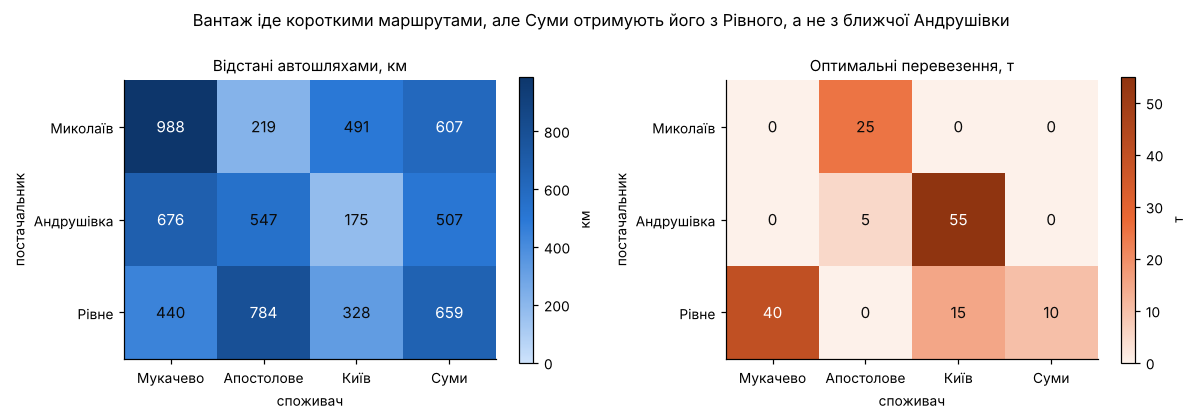

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# Дві різні величини, тому дві окремі послідовні шкали: сині відстані, помаранчеві тонни
сині = LinearSegmentedColormap.from_list('сині', ['#cde2fb', '#2a78d6', '#0d366b'])
помаранчеві = LinearSegmentedColormap.from_list('помаранчеві', ['#fdf1ea', '#eb6834', '#8f3410'])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, M, cmap, назва, одиниці in [(axes[0], D, сині, 'Відстані автошляхами', 'км'),
                                    (axes[1], план_2, помаранчеві, 'Оптимальні перевезення', 'т')]:
    im = ax.imshow(M, cmap=cmap, vmin=0)
    ax.set_xticks(range(n))
    ax.set_xticklabels(споживачі)
    ax.set_yticks(range(m))
    ax.set_yticklabels(постачальники)
    ax.set_xlabel('споживач')
    ax.set_ylabel('постачальник')
    ax.set_title('%s, %s' % (назва, одиниці), fontsize=10)
    for i in range(m):
        for j in range(n):
            value = M[i, j]
            колір = 'white' if value > 0.6 * M.max() else '#0b0b0b'
            ax.text(j, i, '%g' % round(value, 2), ha='center', va='center', color=колір, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.85, label=одиниці)
fig.suptitle('Вантаж іде короткими маршрутами, але Суми отримують його з Рівного, а не з ближчої Андрушівки')
plt.tight_layout()
plt.show()

**Висновок:** Вантаж іде переважно короткими маршрутами (Андрушівка→Київ 175 км, Миколаїв→Апостолове 219 км, Рівне→Мукачево 440 км), але не всюди найкоротшим: Суми отримують 10 т з Рівного за 659 км, а не з Андрушівки за 507 км, бо запас Андрушівки вигідніше віддати Києву; зведена вартість маршруту Андрушівка→Суми лише 1 т·км на тонну, тож план дуже чутливий навіть до кількох кілометрів похибки у відстанях.


---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [ ]:
ІНСТРУМЕНТИ_ШІ = 'Gemini'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі': 'ні',
    'етап 2, побудова моделі в Excel': 'ні',
    'етап 3, код на Python': 'код, перевірено',
    'етапи 4-5, читання та перевірка звіту': 'ні',
    'етап 6, рішення про закупівлю': 'ні',
    'етапи 7-8, перевірка та цілочисельність': 'синтаксис',
    'етапи 9-11, транспортна задача': 'код, перевірено'
}

# Що саме ви перевірили за згенерованим кодом чи текстом - конкретно.
ЩО_ПЕРЕВІРЕНО = 'Основна частина роботи, формалізація та логіка побудови моделей були реалізовані мною самостійно. Інструменти штучного інтелекту використовувалися точково, переважно коли я не був впевнений у точному синтаксисі методів Python або потребував підказки для правильного структурування коду транспортної задачі. Усі згенеровані фрагменти були мною особисто прочитані, перевірені, адаптовані під мої змінні та протестовані на коректність роботи.'

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [ ]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

---
# Крок 13. Фінальна самоперевірка

In [ ]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')